# Complejidad computacional: teórica y medida

Este cuaderno recorre la sección de complejidad del paper:

1. **Entorno** de la medición (CPU, RAM, versiones) y cómo se controla (un solo hilo, calentamiento, 5 repeticiones, mediana y RIQ).
2. **Complejidad teórica** (notación O) de cada modelo y método.
3. **Costo medido** de ajuste, predicción y memoria sobre las 1.928 filas.
4. **Escalado empírico** con submuestras por IES y el exponente log-log frente al teórico.
5. **Costo del protocolo** de evaluación y **costo frente a error** por tarea.

Las cifras oficiales las produce `python run_complejidad.py` (≈ 10 min, con un hilo y sin otra carga) y se leen de `reports/resultados/`. Aquí solo se repite una **demostración corta**
de cómo se mide, porque dentro de un cuaderno el kernel y otras celdas pueden alterar los tiempos.

In [1]:
# Configuración: rutas relativas a la raíz del proyecto, librerías y avisos
import os, sys, json, warnings
from pathlib import Path

ROOT = Path.cwd()
while not (ROOT / "config" / "config.yaml").exists() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
os.chdir(ROOT)
sys.path.insert(0, str(ROOT))
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Image, display

from src.config import load_config
from src.modelado import complejidad as cx
from src.modelado.particion import cargar_dataset

pd.set_option("display.width", 230); pd.set_option("display.max_columns", 40); pd.set_option("display.max_colwidth", 70)
pd.set_option("display.float_format", lambda x: f"{x:.4g}")
cfg = load_config()
R = Path("reports/resultados")
df = cargar_dataset(cfg)
print(f"{len(df)} filas, {df.cod_ies.nunique()} IES")

1928 filas, 295 IES


## 1. Entorno de la medición

In [2]:
entorno = json.loads((R / "complejidad_entorno.json").read_text(encoding="utf-8"))
display(pd.Series(entorno, name="valor").to_frame())

,valor
cpu,12th Gen Intel(R) Core(TM) i5-12500H
nucleos_fisicos,12
hilos_logicos,16
ram_gib,31.6
sistema_operativo,Windows-11-10.0.26200-SP0
python,3.14.6
numpy,2.4.6
pandas,3.0.3
scipy,1.18.0
scikit_learn,1.9.0


## 2. Complejidad teórica

n filas, p variables, T árboles, d profundidad, m variables por división, k componentes, E épocas, h neuronas, I iteraciones de Lloyd, c clusters, K_c candidatos de k.
El **exponente teórico en n** (con las demás cantidades fijas) es el que se compara con el medido más abajo.

In [3]:
teo = pd.DataFrame(cx.teoria()).T
teo["exp"] = teo["exp"].map(lambda e: f"{e[0]:g}" if e[0] == e[1] else f"{e[0]:g}–{e[1]:g}")
display(teo.rename(columns={"exp": "exponente teórico en n"}))

,ajuste,prediccion,memoria,exponente teórico en n
T1 naive (tasa de t-1),O(n),O(1),O(n),1
T2 mediana carácter × sector,O(n log n),O(1),O(n),1–1.2
ridge,O(n p² + p³),O(p),O(n p + p²),1
random_forest,O(T · m · n log n),O(T · d),O(n p + T · nodos),1–1.3
xgboost,O(T · d · n · p) (histogramas),O(T · d),O(n p + T · 2^d),0.9–1.1
Imputación mediana,O(n p),O(n p),O(n p),1
Imputación KNN (k=5),O(n² p) al imputar el entrenamiento,O(n_nuevas · n · p),O(n p) (distancias por bloques),1.8–2
Información mutua (k=15),O(p · n log n),O(n k),O(n p),1–1.3
PCA (90 % varianza),O(n p² + p³),O(n p k),O(n p + p²),1
KernelPCA (RBF),O(n² p + n³) (o O(k n²) con eigensolver parcial),O(n_nuevas · n · (p + k)),O(n²),2–3


## 3. Cómo se mide (demostración corta)

`cx.medir(ajustar, predecir, n_filas, repeticiones, calentamiento)` limita BLAS y OpenMP a un hilo, hace un **calentamiento** y luego las repeticiones; devuelve la mediana y el rango
intercuartílico. La memoria se mide en una ejecución aparte con `tracemalloc` (que enlentece, por eso no se mezcla con los tiempos) y, de forma complementaria, con el RSS muestreado.

In [4]:
pc = {**cx.parametros_complejidad(cfg), "repeticiones": 3, "calentamiento": 1}
rapidos = [c for c in cx.componentes(cfg) if c["nombre"] in ("T1 naive (tasa de t-1)", "T1 C solo historia | ridge", "PCA (90 % varianza)", "K-means (k=6, n_init=10)")]
demo = pd.DataFrame([f for c in rapidos for f in cx.medir_componente(c, df, pc, fracciones=[1.0])])
display(demo[["componente", "n_filas", "ajuste_mediana_s", "ajuste_riq_s", "pred_1000_mediana_ms", "memoria_pico_mib"]])
print("(demostración con 3 repeticiones dentro del cuaderno; las cifras oficiales son las de abajo)")

,componente,n_filas,ajuste_mediana_s,ajuste_riq_s,pred_1000_mediana_ms,memoria_pico_mib
0,T1 naive (tasa de t-1),1928,7.41e-05,9.15e-06,0.007002,0.01811
1,T1 C solo historia | ridge,1928,0.009295,0.000148,1.377,0.4436
2,PCA (90 % varianza),1928,0.003179,0.0001739,0.1882,1.228
3,"K-means (k=6, n_init=10)",1928,0.03214,0.001896,0.2451,1.214


(demostración con 3 repeticiones dentro del cuaderno; las cifras oficiales son las de abajo)


## 4. Costo medido (corrida oficial)

Un hilo, calentamiento + 5 repeticiones, sobre las 1.928 filas. Ajuste en milisegundos (mediana y RIQ), predicción por 1.000 filas y memoria.

In [5]:
c = pd.read_csv(R / "complejidad.csv")
c["ajuste_ms"] = c.ajuste_mediana_s * 1000; c["riq_ms"] = c.ajuste_riq_s * 1000
display(c[["componente", "tipo", "ajuste_ms", "riq_ms", "pred_1000_mediana_ms", "pred_1000_riq_ms", "memoria_pico_mib", "memoria_rss_mib"]].sort_values("ajuste_ms").reset_index(drop=True))

,componente,tipo,ajuste_ms,riq_ms,pred_1000_mediana_ms,pred_1000_riq_ms,memoria_pico_mib,memoria_rss_mib
0,T1 naive (tasa de t-1),linea_base,0.0249,0.0059,0.002282,0.0004149,0.01794,0.02344
1,T2 mediana carácter × sector,linea_base,0.5343,0.0092,0.2538,0.02536,0.2075,0.01953
2,PCA (90 % varianza),preproceso,2.84,0.1941,0.1364,0.01432,1.228,0.02344
3,Imputación mediana,preproceso,4.781,0.0942,0.7262,0.01203,2.196,0.01953
4,T1 C solo historia | ridge,modelo,8.686,0.2428,1.291,0.05545,0.4429,0.01953
5,"K-means (k=6, n_init=10)",preproceso,26,0.7278,0.1884,0.0125,1.213,0.02344
6,T1 C solo historia | xgboost,modelo,38.68,2.291,3.27,0.7205,0.447,0.02734
7,T1 B historia+contexto | xgboost logit,modelo,145.5,2.577,6.131,2.479,2.589,0.03516
8,Imputación KNN (k=5),preproceso,205.8,3.649,107.3,1.987,38.03,35.79
9,Información mutua (k=15),preproceso,374.1,5.977,0.1139,0.00223,2.365,0.02344


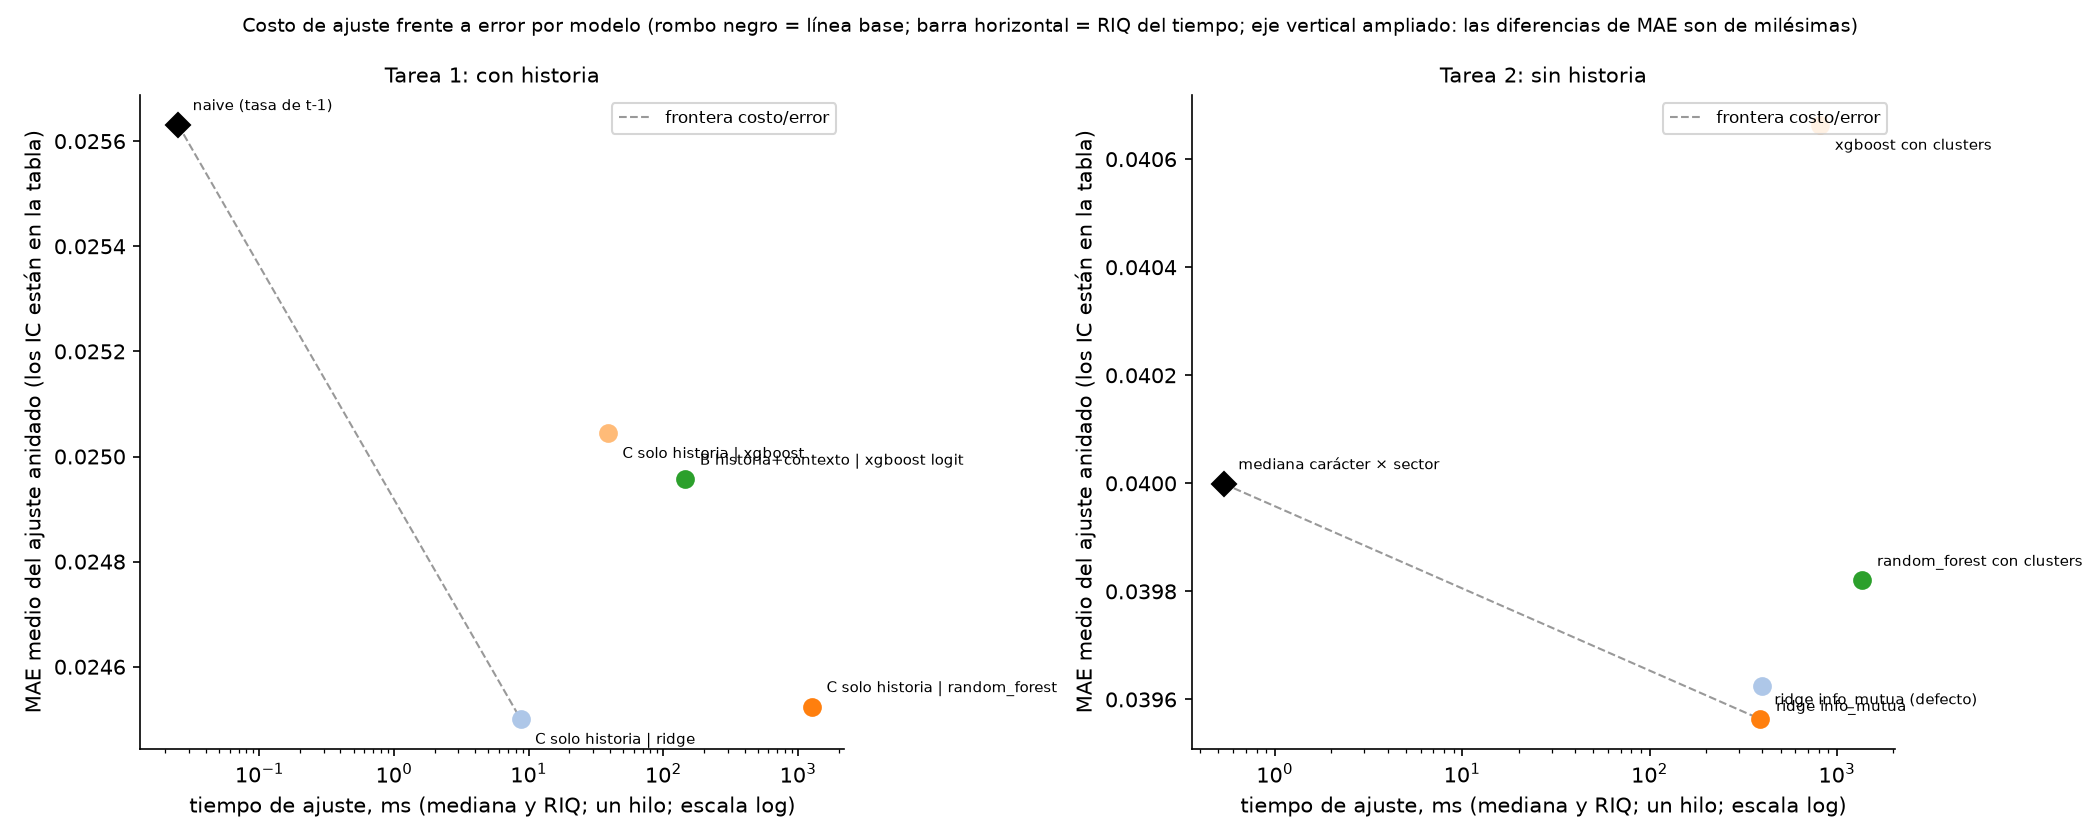

In [6]:
display(Image("reports/figuras/complejidad_costo_error.png"))

## 5. Escalado empírico

Submuestras **por IES** (IES completas, anidadas) del 25, 50, 75 y 100 %. El exponente empírico es la pendiente del tiempo de ajuste contra el número de filas en escala log-log;
**con 4 puntos es aproximado** (se muestra su error estándar). Se compara con el teórico.

Filas por fracción de IES: {0.25: 480, 0.5: 954, 0.75: 1438, 1.0: 1928}


,componente,n_min,n_max,t_min_s,t_max_s,exponente_empirico,error_estandar,r2,exponente_teorico_min,exponente_teorico_max,comparacion
0,T1 naive (tasa de t-1),480,1928,2.18e-05,2.49e-05,0.1044,0.09088,0.3974,1,1,por debajo del teórico
1,T2 mediana carácter × sector,480,1928,0.0004476,0.0005343,0.1281,0.03004,0.9009,1,1.2,por debajo del teórico
2,T1 C solo historia | ridge,480,1928,0.008259,0.008686,0.03349,0.0159,0.6894,1,1,por debajo del teórico
3,T1 C solo historia | random_forest,480,1928,0.5781,1.268,0.5663,0.05326,0.9826,1,1.3,por debajo del teórico
4,T1 C solo historia | xgboost,480,1928,0.03233,0.03868,0.1162,0.05343,0.7027,0.9,1.1,por debajo del teórico
5,T1 B historia+contexto | xgboost logit,480,1928,0.0925,0.1455,0.3202,0.02655,0.9864,0.9,1.1,por debajo del teórico
6,T2 ridge info_mutua sin clusters (ajustado),480,1928,0.1364,0.3958,0.7522,0.02905,0.997,1,1,consistente
7,T2 ridge info_mutua sin clusters (defecto),480,1928,0.1328,0.3874,0.756,0.03131,0.9966,1,1,consistente
8,T2 xgboost con clusters (ajustado),480,1928,0.3138,0.8144,0.6913,0.06434,0.983,0.9,1.1,consistente
9,T2 random_forest con clusters (ajustado),480,1928,0.4637,1.368,0.7707,0.06281,0.9869,1,1.3,consistente


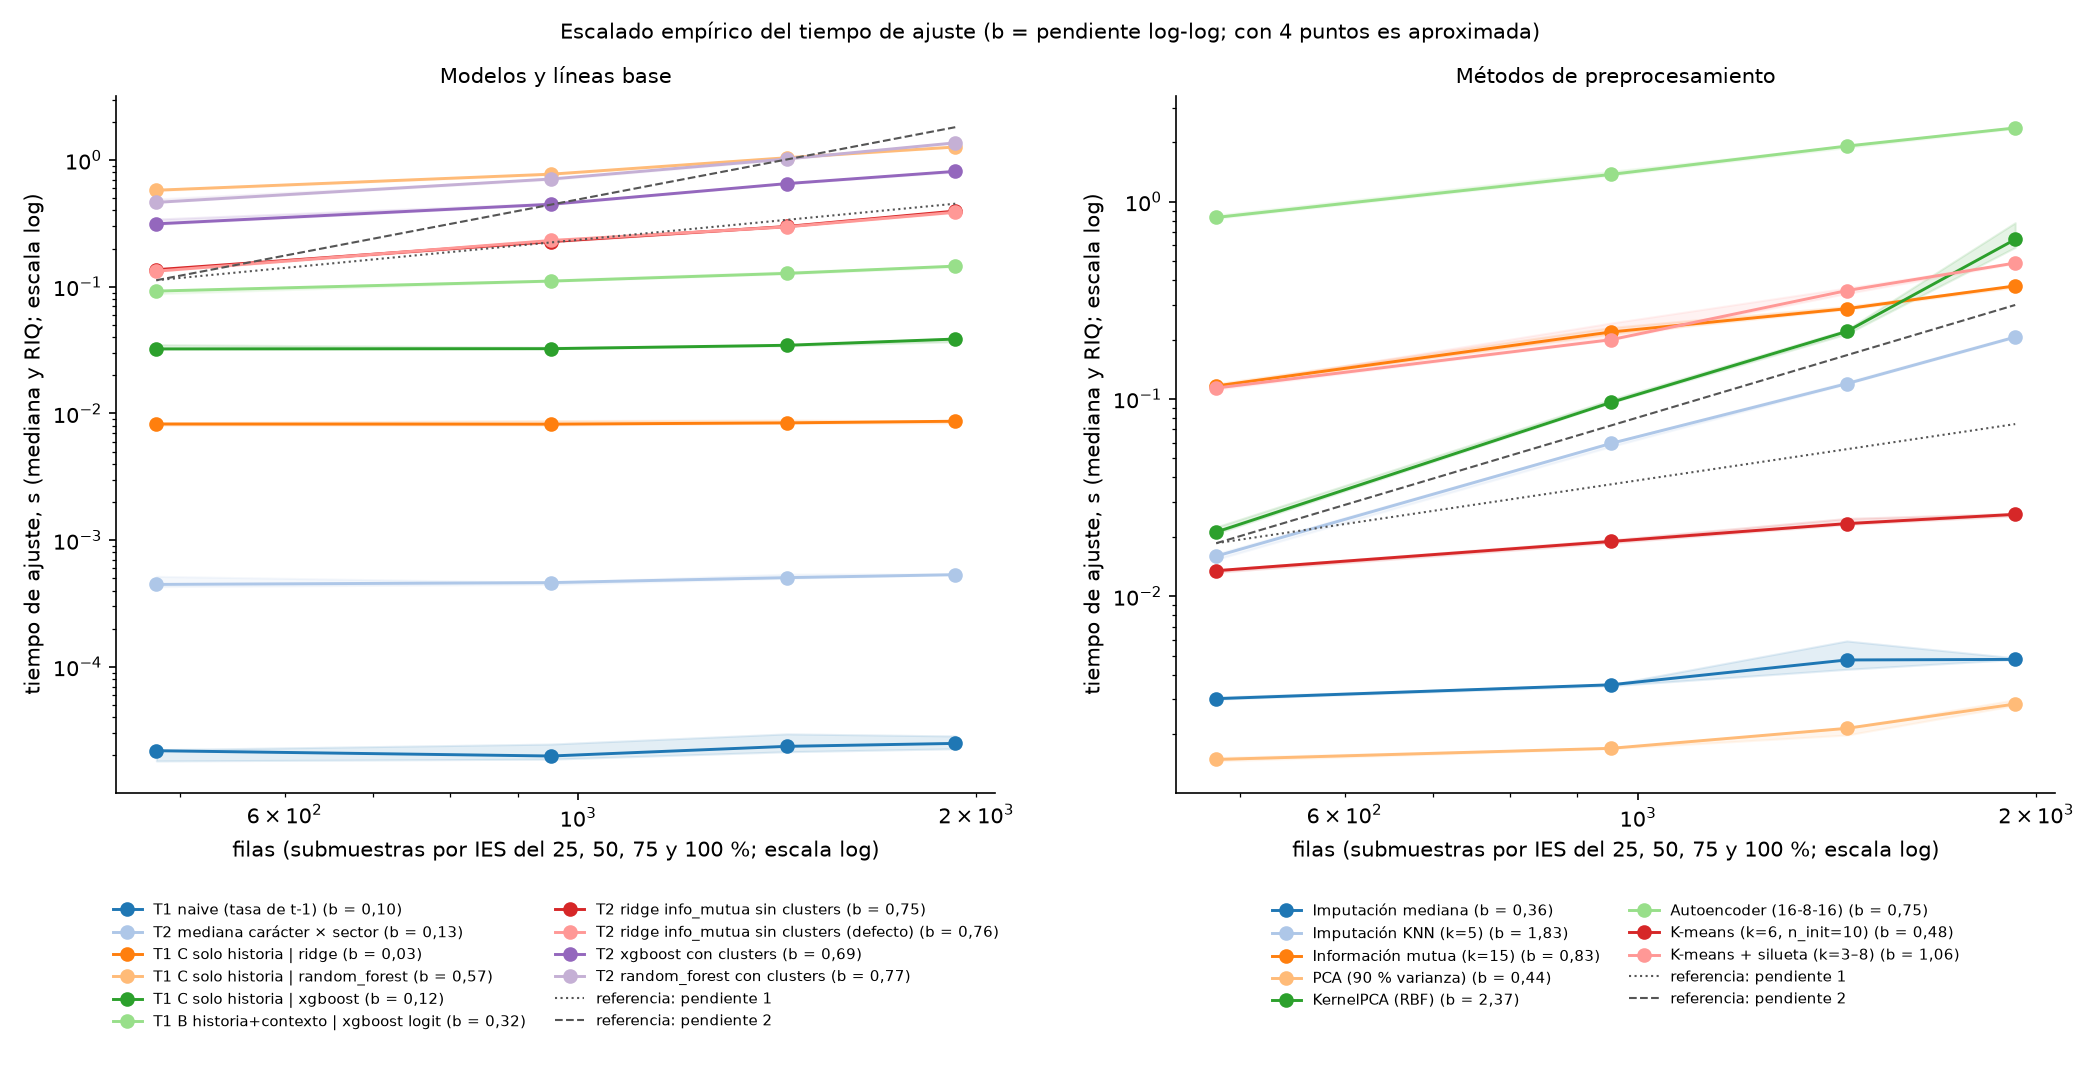

In [7]:
esc = pd.read_csv(R / "complejidad_escalado.csv")
print("Filas por fracción de IES:", esc.groupby("fraccion_ies").n_filas.first().to_dict())
exp = pd.read_csv(R / "complejidad_exponentes.csv")
display(exp[["componente", "n_min", "n_max", "t_min_s", "t_max_s", "exponente_empirico", "error_estandar", "r2", "exponente_teorico_min", "exponente_teorico_max", "comparacion"]])
display(Image("reports/figuras/complejidad_escalado.png"))

In [8]:
# Extrapolación a 10 y 100 veces más filas con el exponente empírico (orden de magnitud; no es una medición)
n0 = int(c.n_filas.max())
ext = exp[["componente", "exponente_empirico", "t_max_s"]].copy()
for f in (10, 100):
    ext[f"t_{f}x_s"] = ext.t_max_s * f ** ext.exponente_empirico
print(f"Con {n0} filas hoy; la matriz n×n de KernelPCA ocuparía {8 * (10 * n0) ** 2 / 2**30:.1f} GiB con 10× filas y {8 * (100 * n0) ** 2 / 2**30:.0f} GiB con 100×")
display(ext.sort_values("exponente_empirico", ascending=False).reset_index(drop=True))

Con 1928 filas hoy; la matriz n×n de KernelPCA ocuparía 2.8 GiB con 10× filas y 277 GiB con 100×


,componente,exponente_empirico,t_max_s,t_10x_s,t_100x_s
0,KernelPCA (RBF),2.375,0.6439,152.5,3.613e+04
1,Imputación KNN (k=5),1.832,0.2058,13.99,950.9
2,K-means + silueta (k=3–8),1.061,0.4888,5.625,64.72
3,Información mutua (k=15),0.8288,0.3741,2.523,17.01
4,T2 random_forest con clusters (ajustado),0.7707,1.368,8.069,47.59
5,T2 ridge info_mutua sin clusters (defecto),0.756,0.3874,2.209,12.59
6,Autoencoder (16-8-16),0.7549,2.365,13.45,76.53
7,T2 ridge info_mutua sin clusters (ajustado),0.7522,0.3958,2.237,12.65
8,T2 xgboost con clusters (ajustado),0.6913,0.8144,4.001,19.65
9,T1 C solo historia | random_forest,0.5663,1.268,4.672,17.21


## 6. Costo del protocolo de evaluación

Número de ajustes de cada etapa (contados en los CSV de resultados) y tiempo de pared de las corridas anteriores.

In [9]:
p = pd.read_csv(R / "complejidad_protocolo.csv")
display(p[["etapa", "configuraciones", "ajustes", "tiempo_pared_s", "paralelismo", "suma_t_ajuste_s"]])
print("Total de ajustes:", int(p.ajustes.sum()), "| tiempo de pared acumulado:", round(p.tiempo_pared_s.sum() / 60, 1), "min")

,etapa,configuraciones,ajustes,tiempo_pared_s,paralelismo,suma_t_ajuste_s
0,"v1: 36 configuraciones, GroupKFold 5",36,180,337,1 proceso,327.2
1,"v2: formulaciones con historia, GroupKFold 5",72,360,874,1 proceso,854.9
2,v3: protocolo repetido 5 × 5,15,375,671,1 proceso,659.4
3,"Tarea 2: cribado (120 configuraciones, 1 semilla)",120,600,827,16 procesos,1.297e+04
4,Tarea 2: confirmación 5 × 5,7,175,42,16 procesos,574.7
5,"Ajuste anidado (7 configuraciones, 5 × 5 externos)",7,16100,1582,16 procesos,2.052e+04
6,Particiones temporales (2 particiones × 7 configuraciones),7,1288,222.1,16 procesos,1031
7,Arranque en frío por municipio 5 × 5,7,175,59.65,16 procesos,791.4
8,Sesgo y sensibilidad (5 escenarios × 5 modelos finales × 25 pliegues),5,625,116.7,16 procesos,390.6


Total de ajustes: 19878 | tiempo de pared acumulado: 78.9 min


## 7. Conclusiones

(Tomadas de `reports/resultados_complejidad.md`; todas las cifras salen de la corrida.)

**1. ¿Qué modelo ofrece la mejor relación costo/error en cada tarea?** (costo = tiempo de ajuste con un hilo sobre las 1.928 filas; error = MAE del ajuste anidado de `resultados_ajuste_temporal.md`)
- **Tarea 1:** la mejor relación costo/error es `T1 C solo historia | ridge`: MAE 0,0245 (+4,4 % frente a la línea base, con firmeza (p t corregida 0,011)) con un ajuste de 8,69 ms, el más barato que logra al menos 90 % de la mejora del mejor modelo (`T1 C solo historia | ridge`, MAE 0,0245, 8,69 ms). La línea base cuesta 0,025 ms (MAE 0,0256). Cuestan más de 3 veces su ajuste sin tener menos error: `T1 C solo historia | random_forest`, `T1 C solo historia | xgboost`, `T1 B historia+contexto | xgboost logit`. Frontera costo/error: `T1 naive (tasa de t-1)`, `T1 C solo historia | ridge`.
- **Tarea 2:** la mejor relación costo/error es `T2 ridge info_mutua sin clusters (defecto)`: MAE 0,0396 (+1,1 % frente a la línea base, sin firmeza estadística (p t corregida 0,562)) con un ajuste de 387 ms, el más barato que logra al menos 90 % de la mejora del mejor modelo (`T2 ridge info_mutua sin clusters (defecto)`, MAE 0,0396, 387 ms). La línea base cuesta 0,534 ms (MAE 0,0400). Cuestan más de 3 veces su ajuste sin tener menos error: `T2 random_forest con clusters (ajustado)`. Frontera costo/error: `T2 mediana carácter × sector`, `T2 ridge info_mutua sin clusters (defecto)`. Como esa mejora no es firme, la línea base (`T2 mediana carácter × sector`, 0,534 ms) es la alternativa razonable: cuesta 725 veces menos.

**2. ¿Algún método escalaría mal con 10 o 100 veces más filas (por ejemplo, datos por estudiante)?** Con 4 puntos el exponente es aproximado; las extrapolaciones suponen que el exponente medido se mantiene.
- `KernelPCA (RBF)`: exponente empírico 2,37 ± 0,19 (teórico 2,0–3,0): de 644 ms hoy pasaría a 2,5 min con 10× filas y a 10,0 h con 100× y una matriz n × n de 2,8 GiB con 10× filas (277,0 GiB con 100×).
- `Imputación KNN (k=5)`: exponente empírico 1,83 ± 0,03 (teórico 1,8–2,0): de 206 ms hoy pasaría a 14,0 s con 10× filas y a 15,8 min con 100×.
- `K-means + silueta (k=3–8)`: en teoría es de orden n² (1,5–2,0) pero con estos tamaños mide 1,06 ± 0,09, porque todavía domina el costo de K-means; con muchas más filas el término n² (la silueta compara cada fila con todas las demás) pasaría a dominar. Como cota superior teórica, con exponente 2 pasaría de 489 ms a 48,9 s con 10× filas y a 81,5 min con 100×; es teoría, no una medición.
- Los demás escalan aproximadamente de forma lineal o casi lineal; el más caro hoy es `Autoencoder (16-8-16)` (2,4 s; exponente 0,75): con 100× filas serían unos 76,5 s.
- Con datos por estudiante (cientos de miles o millones de filas) los métodos de orden n² (KernelPCA, imputación KNN y la selección de k por silueta) dejarían de ser viables tal como están implementados; las alternativas habituales son aproximar el kernel (Nyström o características aleatorias de Fourier), imputar con un método lineal o por submuestra, K-means por lotes (`MiniBatchKMeans`) y calcular la silueta sobre una submuestra. Esto último es una recomendación general, no se midió aquí.